Results Analysis

Main analyses:
- Validate the JSONL and paired baseline/evidence-grounded rows
- Compare category counts and percentages
- Category distributions
- Compare outcomes question-by-question (Category changes)
- Human-review flags 
- Summary



In [11]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("evaluation_results_final.jsonl")
assert DATA_FILE.exists(), (
    f"Can't find {DATA_FILE.resolve()}. Put this notebook in the same folder "
    "as evaluation_results_final.jsonl, or update DATA_FILE."
)

records = []
with DATA_FILE.open("r", encoding="utf-8") as f:
    for line_no, line in enumerate(f, start=1):
        if line.strip():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Invalid JSON on line {line_no}: {e}") from e

df = pd.DataFrame(records)
print("Rows:", len(df))
print("Columns:", len(df.columns))
display(df.head(3))


Rows: 300
Columns: 15


,financebench_id,condition,question,expected_answer,evidence,response,status,numerical_assessment,numerical_reason,numerical_needs_human_review,semantic_assessment,semantic_reason,semantic_needs_human_review,rejected,final_category
0,financebench_id_03029,baseline,What is the FY2018 capital expenditure amount ...,$1577.00,Table of Contents \n3M Company and Subsidiarie...,"10,500 (USD millions) \n*Source: 3M Company F...",completed,Incorrect,The reference answer states $1577.00 USD milli...,False,Correct,The response correctly identifies the capital ...,False,False,Partially Correct
1,financebench_id_03029,evidence_grounded,What is the FY2018 capital expenditure amount ...,$1577.00,Table of Contents \n3M Company and Subsidiarie...,Based solely on the provided cash flow stateme...,completed,Correct,The reference answer $1577.00 matches the 'Pur...,False,Correct,The response correctly identifies the FY2018 c...,False,False,Correct
2,financebench_id_04672,baseline,Assume that you are a public equities analyst....,$8.70,Table of Contents \n3M Company and Subsidiarie...,10.0,completed,Incorrect,The reference answer is $8.70 billion. The evi...,False,Correct,The response provides a numerical value for th...,False,False,Partially Correct


In [12]:
# Structural validation
required = {
    "financebench_id", "condition", "status", "final_category",
    "numerical_assessment", "semantic_assessment",
    "numerical_needs_human_review", "semantic_needs_human_review"
}
missing = required - set(df.columns)
assert not missing, f"Missing expected columns: {sorted(missing)}"

assert len(df) == 300, f"Expected 300 rows; found {len(df)}"
assert df["status"].eq("completed").all(), "Some rows are not completed"
assert not df.duplicated(["financebench_id", "condition"]).any(), "Duplicate question-condition pairs"
assert set(df["condition"].unique()) == {"baseline", "evidence_grounded"}

counts_per_condition = df.groupby("condition")["financebench_id"].nunique()
display(counts_per_condition.rename("unique_questions").to_frame())
assert (counts_per_condition == 150).all(), "Expected 150 unique questions per condition"

print("Validation passed: 300 completed rows, 150 questions per condition, no duplicate pairs.")


,unique_questions
condition,
baseline,150
evidence_grounded,150


Validation passed: 300 completed rows, 150 questions per condition, no duplicate pairs.


## Category distribution (percentages)

In [13]:
category_order = ["Correct", "Partially Correct", "Incorrect", "Rejected"]
category_counts = (
    df.groupby(["condition", "final_category"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=category_order, fill_value=0)
)
category_rates = category_counts.div(df.groupby("condition").size(), axis=0) * 100

print("Category counts:")
display(category_counts)
print("Category rates (%):")
display(category_rates.round(2))

category_counts.to_csv("category_counts.csv")
category_rates.round(4).to_csv("category_rates_percent.csv")


Category counts:


final_category,Correct,Partially Correct,Incorrect,Rejected
condition,,,,
baseline,17,41,92,0
evidence_grounded,118,21,11,0


Category rates (%):


final_category,Correct,Partially Correct,Incorrect,Rejected
condition,,,,
baseline,11.33,27.33,61.33,0.0
evidence_grounded,78.67,14.00,7.33,0.0


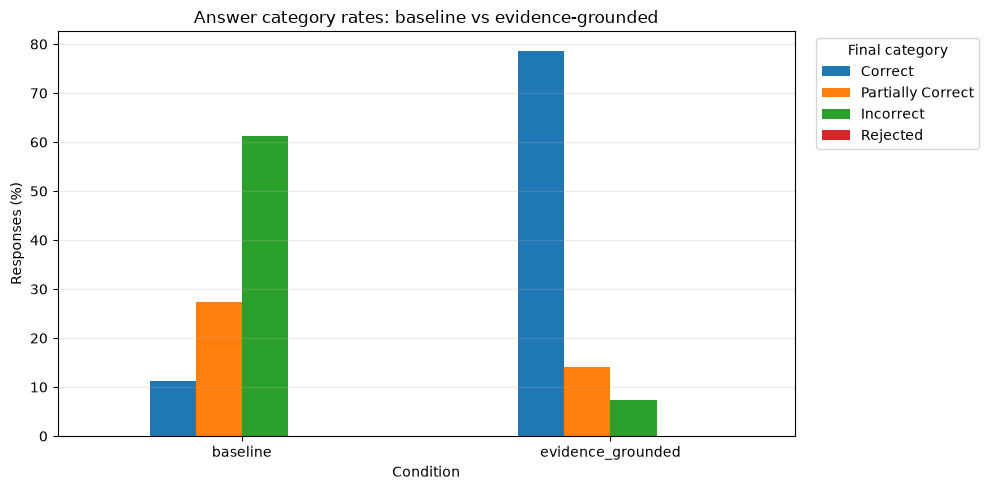

In [14]:
# Plot category percentages as grouped bars
ax = category_rates.reindex(index=["baseline", "evidence_grounded"]).plot(
    kind="bar", figsize=(10, 5), rot=0
)
ax.set_title("Answer category rates: baseline vs evidence-grounded")
ax.set_xlabel("Condition")
ax.set_ylabel("Responses (%)")
ax.legend(title="Final category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("category_rates.png", dpi=180, bbox_inches="tight")
plt.show()


## Paired, Category Changes

In [15]:
paired = df.pivot(
    index="financebench_id",
    columns="condition",
    values="final_category"
).reset_index()

assert paired["baseline"].notna().all() and paired["evidence_grounded"].notna().all()

transition = pd.crosstab(
    paired["baseline"],
    paired["evidence_grounded"],
    rownames=["Baseline category"],
    colnames=["Evidence-grounded category"],
    dropna=False
)
display(transition)
transition.to_csv("category_transition_matrix.csv")

changed = paired[paired["baseline"] != paired["evidence_grounded"]].copy()
print(f"Questions whose category changed: {len(changed)} / {len(paired)} "
      f"({len(changed) / len(paired) * 100:.1f}%)")
display(changed.head(10))
changed.to_csv("question_level_category_changes.csv", index=False)


Evidence-grounded category,Correct,Incorrect,Partially Correct
Baseline category,,,
Correct,15,0,2
Incorrect,77,7,8
Partially Correct,26,4,11


Questions whose category changed: 117 / 150 (78.0%)


condition,financebench_id,baseline,evidence_grounded
5,financebench_id_00216,Partially Correct,Correct
6,financebench_id_00222,Incorrect,Correct
8,financebench_id_00288,Incorrect,Partially Correct
10,financebench_id_00302,Partially Correct,Incorrect
11,financebench_id_00382,Partially Correct,Correct
12,financebench_id_00394,Incorrect,Correct
13,financebench_id_00407,Partially Correct,Correct
18,financebench_id_00494,Incorrect,Correct
19,financebench_id_00499,Incorrect,Correct
20,financebench_id_00517,Incorrect,Correct


## Human-review flags

In [16]:
def truthy_flag(series):
    # Handle JSON booleans and common string representations safely.
    return series.map(lambda x: x is True or str(x).strip().lower() == "true")

df["needs_human_review"] = (
    truthy_flag(df["numerical_needs_human_review"]) |
    truthy_flag(df["semantic_needs_human_review"])
)

review_summary = (
    df.groupby("condition")
      .agg(
          responses=("financebench_id", "size"),
          numerical_review=("numerical_needs_human_review", lambda s: int(truthy_flag(s).sum())),
          semantic_review=("semantic_needs_human_review", lambda s: int(truthy_flag(s).sum())),
          either_review=("needs_human_review", "sum")
      )
)
display(review_summary)

review_rows = df[df["needs_human_review"]].copy()
print("Rows explicitly flagged for review:", len(review_rows))
display(review_rows[[
    "financebench_id", "condition", "question", "expected_answer", "response",
    "numerical_assessment", "numerical_reason", "semantic_assessment",
    "semantic_reason", "final_category"
]].head(20))
review_rows.to_csv("rows_flagged_for_human_review.csv", index=False)


,responses,numerical_review,semantic_review,either_review
condition,,,,
baseline,150,4,3,5
evidence_grounded,150,6,1,7


Rows explicitly flagged for review: 12


,financebench_id,condition,question,expected_answer,response,numerical_assessment,numerical_reason,semantic_assessment,semantic_reason,final_category
3,financebench_id_04672,evidence_grounded,Assume that you are a public equities analyst....,$8.70,Based solely on the provided balance sheet evi...,Correct,The reference answer is $8.70 billion. The evi...,Correct,The response correctly identifies the net PP&E...,Correct
33,financebench_id_00540,evidence_grounded,Roughly how many times has AES Corporation sol...,AES has converted inventory 9.5 times in FY 2022.,"Based solely on the provided evidence, the inv...",Incorrect,The reference answer states AES has converted ...,Correct,The response correctly identifies that convent...,Partially Correct
44,financebench_id_01935,baseline,What was the key agenda of the AMCOR's 8k fili...,"Amcor Finance (USA), Inc. and Amcor Flexibles ...",The key event reported in AMCOR's Form 8-K fil...,Incorrect,The response claims a sale of Australian opera...,Incorrect,The response mentions a sale of Australian ope...,Incorrect
54,financebench_id_01936,baseline,What is the nature & purpose of AMCOR's restru...,87% of the total restructuring liability is re...,AMCOR's restructuring liability as of Q2 FY202...,Incorrect,The reference answer states that 87% of the to...,Incorrect,The reference answer states that 87% of the to...,Incorrect
55,financebench_id_01936,evidence_grounded,What is the nature & purpose of AMCOR's restru...,87% of the total restructuring liability is re...,The evidence provided is insufficient to answe...,Incorrect,The reference answer states that 87% of the to...,Correct,The response correctly identifies that the evi...,Partially Correct
106,financebench_id_00288,baseline,Was there any drop in Cash & Cash equivalents ...,"Yes, there was a decline of ~42% between FY202...",Company name is required to answer this questi...,Incorrect,The reference answer claims a ~42% decline in ...,Incorrect,The response states that the company name is r...,Incorrect
157,financebench_id_01244,evidence_grounded,Has CVS Health paid dividends to common shareh...,"Yes, CVS paid a $ 0.55 dividend per share ever...","The evidence provided states: ""During 2022, 20...",Incorrect,The reference answer states CVS paid a $0.55 d...,Correct,The response correctly identifies that the evi...,Partially Correct
204,financebench_id_03718,baseline,What is Lockheed Martin's 2 year total revenue...,0.4%,-0.4%,Correct,The reference answer of 0.4% is calculated fro...,Incorrect,The response states '-0.4%' but the reference ...,Partially Correct
215,financebench_id_01911,evidence_grounded,What was MGM's interest coverage ratio using F...,"As adjusted EBIT is negative, coverage ratio i...",The evidence provided does not contain a figur...,Incorrect,The reference answer states that the coverage ...,Correct,The response correctly identifies that the evi...,Partially Correct
232,financebench_id_04080,baseline,When primarily referencing the income statemen...,3.46,4.90,Incorrect,"The reference answer is 3.46, but the model re...",Incorrect,The response provides a numerical value withou...,Incorrect


## Numerical vs semantic assessments


In [17]:
print("Numerical assessment counts:")
display(pd.crosstab(df["condition"], df["numerical_assessment"], margins=True))

print("Semantic assessment counts:")
display(pd.crosstab(df["condition"], df["semantic_assessment"], margins=True))

print("Numerical assessment vs semantic assessment:")
display(pd.crosstab(df["numerical_assessment"], df["semantic_assessment"], margins=True))

# Inspect rows where the numerical assessment is N/A.
na_numeric = df[df["numerical_assessment"].astype(str).str.strip().str.upper().eq("N/A")]
print("Rows with numerical assessment N/A:", len(na_numeric))
display(na_numeric[[
    "financebench_id", "condition", "question", "expected_answer", "response",
    "semantic_assessment", "final_category"
]].head(25))
na_numeric.to_csv("numerical_na_rows_for_audit.csv", index=False)


Numerical assessment counts:


numerical_assessment,Correct,Incorrect,N/A,All
condition,,,,
baseline,14,128,8,150
evidence_grounded,105,29,16,150
All,119,157,24,300


Semantic assessment counts:


semantic_assessment,Correct,Incorrect,All
condition,,,
baseline,55,95,150
evidence_grounded,138,12,150
All,193,107,300


Numerical assessment vs semantic assessment:


semantic_assessment,Correct,Incorrect,All
numerical_assessment,,,
Correct,115,4,119
Incorrect,58,99,157
N/A,20,4,24
All,193,107,300


Rows with numerical assessment N/A: 24


,financebench_id,condition,question,expected_answer,response,semantic_assessment,final_category
7,financebench_id_01226,evidence_grounded,What drove operating margin change as of FY202...,Operating Margin for 3M in FY2022 has decrease...,The evidence provided is insufficient to answe...,Correct,Correct
45,financebench_id_01935,evidence_grounded,What was the key agenda of the AMCOR's 8k fili...,"Amcor Finance (USA), Inc. and Amcor Flexibles ...",The evidence provided does not contain informa...,Incorrect,Incorrect
50,financebench_id_01148,baseline,What industry does AMCOR primarily operate in?,Amcor is a global leader in packaging producti...,AMCOR primarily operates in the **aluminum pac...,Correct,Correct
51,financebench_id_01148,evidence_grounded,What industry does AMCOR primarily operate in?,Amcor is a global leader in packaging producti...,packaging industry,Correct,Correct
64,financebench_id_00995,baseline,What are the major products and services that ...,AMD sells server microprocessors (CPUs) and gr...,AMD's major products and services for FY22 wer...,Correct,Correct
65,financebench_id_00995,evidence_grounded,What are the major products and services that ...,AMD sells server microprocessors (CPUs) and gr...,"Based solely on the provided evidence, AMD sel...",Correct,Correct
69,financebench_id_00917,evidence_grounded,What drove operating margin change as of the F...,The decrease in AMD's operating income was pri...,"Based **strictly on the provided evidence**, t...",Correct,Correct
78,financebench_id_01028,baseline,What are the geographies that American Express...,"United States, EMEA, APAC, and LACC","As of 2022, American Express primarily operate...",Incorrect,Incorrect
89,financebench_id_01981,evidence_grounded,Was American Express able to retain card membe...,Yes,Yes. \n\n**Reasoning**: The provided evidence...,Correct,Correct
110,financebench_id_01902,baseline,Which Best Buy product category performed the ...,The entertainment segment experienced the high...,This question cannot be answered with certaint...,Incorrect,Incorrect


## Largest disagreements and suspicious cases




In [18]:
# Cases where numerical and semantic labels disagree, excluding N/A
num = df["numerical_assessment"].astype(str).str.strip()
sem = df["semantic_assessment"].astype(str).str.strip()
disagreement = df[(num.str.upper() != "N/A") & (num != sem)].copy()

print("Numerical/semantic label disagreements:", len(disagreement))
display(disagreement[[
    "financebench_id", "condition", "question", "expected_answer", "response",
    "numerical_assessment", "numerical_reason",
    "semantic_assessment", "semantic_reason", "final_category"
]].head(30))
disagreement.to_csv("numerical_semantic_disagreements.csv", index=False)

# List every row with a non-N/A numerical label, to support a manual audit of qualitative questions.
print("Potential audit sample — qualitative questions should be checked manually.")
display(df[[
    "financebench_id", "condition", "question", "numerical_assessment",
    "numerical_reason", "semantic_assessment", "final_category"
]].sample(min(20, len(df)), random_state=42))


Numerical/semantic label disagreements: 62


,financebench_id,condition,question,expected_answer,response,numerical_assessment,numerical_reason,semantic_assessment,semantic_reason,final_category
0,financebench_id_03029,baseline,What is the FY2018 capital expenditure amount ...,$1577.00,"10,500 (USD millions) \n*Source: 3M Company F...",Incorrect,The reference answer states $1577.00 USD milli...,Correct,The response correctly identifies the capital ...,Partially Correct
2,financebench_id_04672,baseline,Assume that you are a public equities analyst....,$8.70,10.0,Incorrect,The reference answer is $8.70 billion. The evi...,Correct,The response provides a numerical value for th...,Partially Correct
16,financebench_id_02987,baseline,What is the FY2019 fixed asset turnover ratio ...,24.26,5.57,Incorrect,The reference answer is 24.26. The model respo...,Correct,The response provides a numerical value for th...,Partially Correct
18,financebench_id_07966,baseline,What is the FY2017 - FY2019 3 year average of ...,1.9%,11.8% \n\n*(Based on Activision Blizzard's pu...,Incorrect,"The reference answer states 1.9%, but the mode...",Correct,The response provides the 3-year average capex...,Partially Correct
33,financebench_id_00540,evidence_grounded,Roughly how many times has AES Corporation sol...,AES has converted inventory 9.5 times in FY 2022.,"Based solely on the provided evidence, the inv...",Incorrect,The reference answer states AES has converted ...,Correct,The response correctly identifies that convent...,Partially Correct
34,financebench_id_10420,baseline,Based on the information provided primarily in...,-0.02,The question does not provide AES's financial ...,Incorrect,The reference answer of -0.02 is incorrect. Th...,Correct,The response correctly identifies that the nec...,Partially Correct
37,financebench_id_06655,evidence_grounded,What is Amazon's FY2017 days payable outstandi...,93.86,To calculate Amazon's FY2017 days payable outs...,Incorrect,"The model response calculates DPO as 93.85, bu...",Correct,The response correctly identifies the relevant...,Partially Correct
46,financebench_id_00799,baseline,Has AMCOR's quick ratio improved or declined b...,The quick ratio has slightly improved from 0.6...,AMCOR's quick ratio is **not a relevant metric...,Incorrect,The reference answer states that the quick rat...,Correct,The response correctly identifies that the qui...,Partially Correct
55,financebench_id_01936,evidence_grounded,What is the nature & purpose of AMCOR's restru...,87% of the total restructuring liability is re...,The evidence provided is insufficient to answe...,Incorrect,The reference answer states that 87% of the to...,Correct,The response correctly identifies that the evi...,Partially Correct
56,financebench_id_01928,baseline,What Was AMCOR's Adjusted Non GAAP EBITDA for ...,"AMCOR's Adj. EBITDA was $2,018mn in FY 2023",AMCOR reported Adjusted Non GAAP EBITDA of **$...,Incorrect,The reference answer states AMCOR's Adjusted N...,Correct,The model response correctly identifies AMCOR'...,Partially Correct


Potential audit sample — qualitative questions should be checked manually.


,financebench_id,condition,question,numerical_assessment,numerical_reason,semantic_assessment,final_category
203,financebench_id_03031,evidence_grounded,What is Lockheed Martin's FY2021 net working c...,Correct,The model response correctly calculates net wo...,Correct,Correct
266,financebench_id_00283,baseline,How much does Pfizer expect to pay to spin off...,Incorrect,The question asks for future payments Pfizer e...,Incorrect,Incorrect
152,financebench_id_00790,baseline,Is CVS Health a capital-intensive business bas...,Incorrect,The model response claims CVS Health has low c...,Incorrect,Incorrect
9,financebench_id_01865,evidence_grounded,"If we exclude the impact of M&A, which segment...",Correct,The reference answer states that the consumer ...,Correct,Correct
233,financebench_id_04080,evidence_grounded,When primarily referencing the income statemen...,Correct,The calculation uses the correct values from t...,Correct,Correct
226,financebench_id_03282,baseline,What is Netflix's year end FY2017 total curren...,Incorrect,The model response states that no financial da...,Incorrect,Incorrect
196,financebench_id_02049,baseline,"Looking at VaR, did the risk that JPM faced in...",Incorrect,The reference answer states that average total...,Correct,Partially Correct
109,financebench_id_00460,evidence_grounded,Was there any change in the number of Best Buy...,Incorrect,The model response states that the total numbe...,Correct,Partially Correct
5,financebench_id_00499,evidence_grounded,Is 3M a capital-intensive business based on FY...,Correct,The model response correctly calculates the fi...,Correct,Correct
175,financebench_id_00711,evidence_grounded,Roughly how many times has JnJ sold its invent...,Correct,The inventory turnover ratio calculation uses ...,Correct,Correct


## Summary

In [ ]:
for condition in ["baseline", "evidence_grounded"]:
    n = int((df["condition"] == condition).sum())
    counts = df.loc[df["condition"] == condition, "final_category"].value_counts()
    correct = int(counts.get("Correct", 0))
    partial = int(counts.get("Partially Correct", 0))
    incorrect = int(counts.get("Incorrect", 0))
    rejected = int(counts.get("Rejected", 0))
    print(
        f"{condition}: n={n}; Correct={correct} ({correct/n*100:.1f}%); "
        f"Partially Correct={partial} ({partial/n*100:.1f}%); "
        f"Incorrect={incorrect} ({incorrect/n*100:.1f}%); "
        f"Rejected={rejected} ({rejected/n*100:.1f}%)."
    )

baseline_correct = (df.query("condition == 'baseline'")["final_category"] == "Correct").mean() * 100
evidence_correct = (df.query("condition == 'evidence_grounded'")["final_category"] == "Correct").mean() * 100
baseline_incorrect = (df.query("condition == 'baseline'")["final_category"] == "Incorrect").mean() * 100
evidence_incorrect = (df.query("condition == 'evidence_grounded'")["final_category"] == "Incorrect").mean() * 100

print()
print(f"Correct-rate difference (evidence-grounded minus baseline): {evidence_correct-baseline_correct:+.1f} percentage points")
print(f"Incorrect-rate difference (evidence-grounded minus baseline): {evidence_incorrect-baseline_incorrect:+.1f} percentage points")
print("\nInterpretation caution: these figures reflect the current automated labels. Validate a sample manually before presenting them as definitive findings.")
